# 01 Data and features

In APP scams the victim sends the money themselves (fake bank call, fake relative, fake investment). The bank sees the real customer and the right PIN so the payment goes through.

We look at behaviour instead: new recipient, amount much bigger than usual, many payments in a short time, night, online, PIN errors.

Steps: load TabFormer (IBM synthetic card transactions, comes with the lab image), compute features with the same engine the API uses, check which signals matter, save everything for training and for the service.

In [1]:
import os, sys, time, json, platform
from pathlib import Path
ROOT = Path.cwd().parent if (Path.cwd().parent / "safepause").exists() else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
from safepause import config
print("project:", ROOT, "| machine:", platform.machine(), "| CPUs:", os.cpu_count())

project: /home/ibm-user/shared/safepause | machine: s390x | CPUs: 3


## Platform check

In [2]:
cpuinfo = open("/proc/cpuinfo").read() if os.path.exists("/proc/cpuinfo") else ""
features_line = next((l for l in cpuinfo.splitlines() if l.startswith("features")), "")
machine_line = next((l for l in cpuinfo.splitlines() if "machine" in l), "")
print("architecture :", platform.machine())
print("machine      :", machine_line.strip()[:120])
print("NNPA (Telum AI accelerator) available:", "nnpa" in features_line.split())

architecture : s390x
machine      : processor 0: version = FF,  identification = 07DFD8,  machine = 9175
NNPA (Telum AI accelerator) available: True


## Load data
transactions_history.csv from the lab image. The loader also works with the full 24M row file (reads it in chunks).

In [3]:
from safepause.data import find_dataset, load_tabformer, time_split
USER_MOD, MIN_YEAR = None, None    # None = automatic (whole lab file; subset if the 24M-row file is used)
path = find_dataset()
print("dataset:", path, f"({os.path.getsize(path)/1e9:.2f} GB)")
t0 = time.perf_counter()
df = load_tabformer(path, user_mod=USER_MOD, min_year=MIN_YEAR)
print(f"loaded {len(df):,} transactions, {df.user.nunique()} customers, "
      f"{df.is_fraud.sum():,} fraud ({df.is_fraud.mean()*100:.3f}%) in {time.perf_counter()-t0:.0f}s")
df.head()

dataset: /home/ibm-user/transactions_history.csv (0.02 GB)


read 245,864 rows, kept 245,864


loaded 245,864 transactions, 19 customers, 271 fraud (0.110%) in 1s


,tx_id,user,card,ts,amount,merchant,mcc,city,state,use_chip,errors,is_fraud
0,0,4,0,1999-11-26 15:03:00,1300.73,6515854639642454768,3066,Santa Clara,CA,Swipe Transaction,,0
1,1,4,0,1999-12-01 09:20:00,106.61,-7146670748125200898,5970,San Francisco,CA,Swipe Transaction,,0
2,2,4,0,1999-12-01 09:33:00,16.52,9057735476014445185,5311,San Francisco,CA,Swipe Transaction,,0
3,3,4,0,1999-12-01 12:55:00,9.93,112925206871091074,5541,San Francisco,CA,Swipe Transaction,,0
4,4,4,0,1999-12-01 15:27:00,81.36,9057735476014445185,5311,San Francisco,CA,Swipe Transaction,,0


## How fraud looks in the data

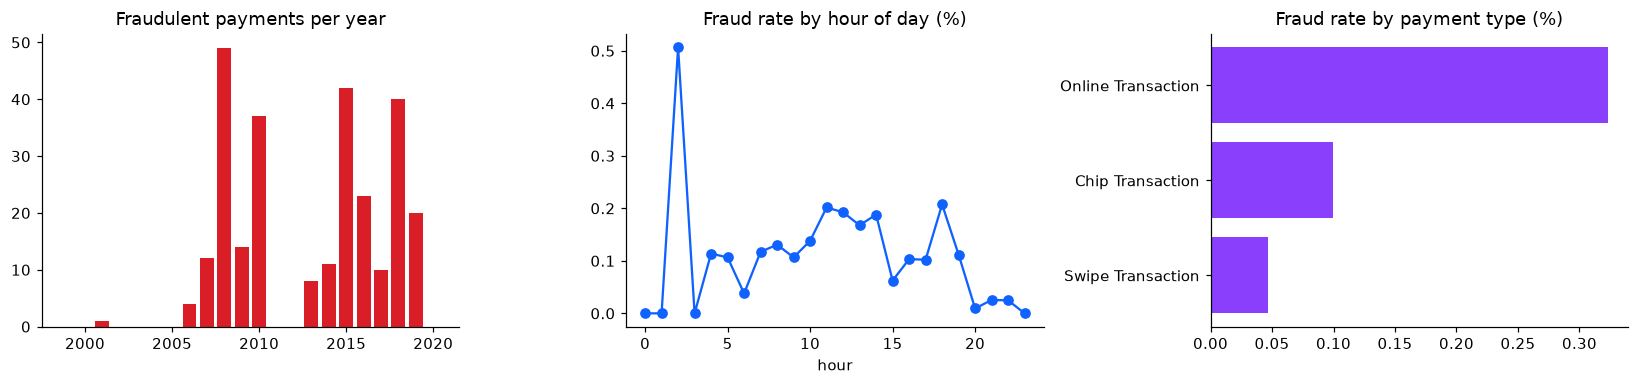

median amount  normal: $44.04   fraud: $87.74


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
yr = df.groupby(df.ts.dt.year).is_fraud.agg(["sum", "mean"])
ax[0].bar(yr.index, yr["sum"], color="#da1e28"); ax[0].set_title("Fraudulent payments per year")
hr = df.groupby(df.ts.dt.hour).is_fraud.mean() * 100
ax[1].plot(hr.index, hr.values, color="#0f62fe", marker="o"); ax[1].set_title("Fraud rate by hour of day (%)"); ax[1].set_xlabel("hour")
ch = df.groupby("use_chip").is_fraud.mean().sort_values() * 100
ax[2].barh(ch.index, ch.values, color="#8a3ffc"); ax[2].set_title("Fraud rate by payment type (%)")
plt.tight_layout(); plt.savefig(config.FIGURES / "01_fraud_eda.png", bbox_inches="tight"); plt.show()
print("median amount  normal: $%.2f   fraud: $%.2f" % (df.loc[df.is_fraud==0,"amount"].abs().median(),
                                                     df.loc[df.is_fraud==1,"amount"].abs().median()))

## Features
Split by time: train on old data, tune on the next period, test on the latest one. Engine state is saved at the start of the test period and the API continues from there.

In [5]:
from safepause.features import build_features, FEATURES
val_start, test_start = time_split(df, val_frac=0.1, test_frac=0.2)
t0 = time.perf_counter()
X, prev_idx, snapshot = build_features(df, snapshot_at=test_start)
el = time.perf_counter() - t0
y = df.is_fraud.to_numpy()
print(f"{len(X):,} payments x {X.shape[1]} features in {el:.0f}s  ->  {len(X)/el:,.0f} payments/s single-threaded")
print("train:", df.ts[0].date(), "->", df.ts[val_start].date(), "| val ->", df.ts[test_start].date(),
      "| test ->", df.ts.iloc[-1].date())
pd.DataFrame(X[:5], columns=FEATURES).round(2)

features: 0/245,864

features: 200,000/245,864

features: 245,864/245,864 done
245,864 payments x 21 features in 6s  ->  41,994 payments/s single-threaded
train: 1999-11-26 -> 2016-04-10 | val -> 2018-01-10 | test -> 2020-02-28


,log_amount,refund,amount_ratio,amount_z,spend_24h_ratio,new_merchant,new_mcc,new_city,online,has_error,...,night,tx_1h,tx_24h,log_secs_since_prev,log_user_history,mcc_code,foreign,new_state,new_merch_24h,new_frac_recent
0,7.17,0.0,1.00,0.00,1.00,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,14.77,0.00,3066.0,0.0,1.0,1.0,1.0
1,4.68,0.0,0.08,-20.00,0.08,1.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,12.93,0.69,5970.0,0.0,0.0,1.0,1.0
2,2.86,0.0,0.02,-1.15,0.17,1.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,6.66,1.10,5311.0,0.0,0.0,2.0,1.0
3,2.39,0.0,0.02,-0.79,0.28,1.0,1.0,0.0,0.0,0.0,...,0.0,0.0,2.0,9.40,1.39,5541.0,0.0,0.0,3.0,1.0
4,4.41,0.0,0.23,-0.51,0.60,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,3.0,9.12,1.61,5311.0,0.0,0.0,3.0,1.0


## Signal lift (how much more likely fraud is when a signal fires)

,signal,% of payments,fraud lift (x base rate)
0,first payment to recipient,2.40,17.06
1,amount >= 3x usual,3.24,7.73
2,online payment,18.75,2.93
3,night 00-06,4.74,1.09
4,>=3 payments in 1h,1.94,3.04
5,errors (PIN/CVV),1.79,2.48
6,rule: new_payee_big,0.32,22.07
7,rule: burst,1.94,3.04
8,rule: night_big,0.64,4.61
9,rule: online_new,0.24,77.81


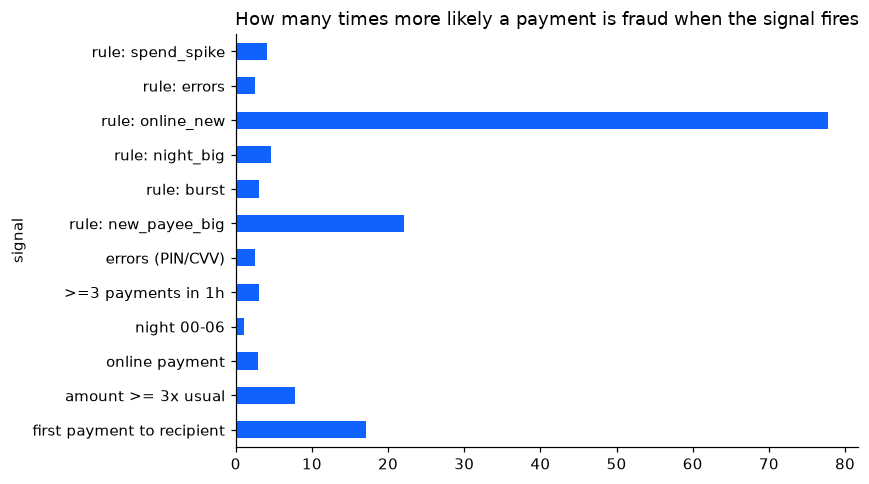

In [6]:
from safepause.scorer import rule_matrix, RULE_CODES
F = pd.DataFrame(X, columns=FEATURES); F["fraud"] = y
base = y.mean()
rows = []
for name, mask in [("first payment to recipient", F.new_merchant > 0),
                   ("amount >= 3x usual", F.amount_ratio >= 3),
                   ("online payment", F.online > 0),
                   ("night 00-06", F.night > 0),
                   (">=3 payments in 1h", F.tx_1h >= 3),
                   ("errors (PIN/CVV)", F.has_error > 0)]:
    rows.append((name, mask.mean() * 100, F.fraud[mask].mean() / base))
R = rule_matrix(X)
for i, code in enumerate(RULE_CODES):
    rows.append(("rule: " + code, R[:, i].mean() * 100, y[R[:, i]].mean() / base if R[:, i].any() else 0))
lift = pd.DataFrame(rows, columns=["signal", "% of payments", "fraud lift (x base rate)"]).round(2)
display(lift)
ax = lift.set_index("signal")["fraud lift (x base rate)"].plot.barh(figsize=(8, 4.5), color="#0f62fe")
ax.set_title("How many times more likely a payment is fraud when the signal fires"); plt.tight_layout()
plt.savefig(config.FIGURES / "01_signal_lift.png", bbox_inches="tight"); plt.show()

## Save

In [7]:
np.savez_compressed(config.DATASET_NPZ, X=X, y=y, prev_idx=prev_idx,
                    val_start=val_start, test_start=test_start, amount=df.amount.to_numpy())
config.ENGINE_STATE.write_bytes(snapshot)
cols = ["tx_id", "user", "ts", "amount", "merchant", "mcc", "city", "state", "use_chip", "errors", "is_fraud"]
df.iloc[test_start:][cols].to_csv(config.STREAM_CSV, index=False)
json.dump({"rows": len(df), "customers": int(df.user.nunique()), "fraud": int(y.sum()),
           "train": int(val_start), "val": int(test_start - val_start), "test": int(len(df) - test_start)},
          open(config.ARTIFACTS / "data_summary.json", "w"), indent=2)
print("saved:", config.DATASET_NPZ.name, config.ENGINE_STATE.name, config.STREAM_CSV.name)

saved: features.npz engine_state.pkl stream_test.csv
